<a href="https://colab.research.google.com/github/AndresMontesDeOca/vision_computadora_II/blob/VpC2_2026/TP/Couter_Strike.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline de Detección de Objetos en Counter-Strike
Este notebook contiene el pipeline completo para el entrenamiento de modelos de detección de objetos en Counter-Strike. Está dividido en dos grandes fases:
1. **Análisis Exploratorio de Datos (EDA):** Evaluación del dataset, balanceo de clases, dimensiones de imágenes, formatos e identidad cromática en el espacio HSV.
2. **Entrenamiento y Monitoreo (YOLOv11 + W&B):** Configuración de la telemetría de experimentos con Weights & Biases y el entrenamiento del modelo.

### 🛠️ Configuración de Parámetros Globales del Experimento
Define aquí las variables globales y el optimizador que se utilizará en todo el pipeline.

In [1]:
#@title Parámetros de Entrenamiento { run: "auto" }

# Selecciona la versión del modelo preentrenado de YOLO (Soporta YOLOv11 n, s, m, l, x)
yolo_model_version = "yolo11n.pt" #@param ["yolo11n.pt", "yolo11s.pt", "yolo11m.pt", "yolo11l.pt", "yolo11x.pt"] {allow-input: true}

# Selecciona el optimizador ('AdamW' o 'GD')
optimizer_type = "AdamW" #@param ["AdamW", "GD"] {allow-input: true}

print(f"Configuración seleccionada de forma global:")
print(f" - Modelo: {yolo_model_version}")
print(f" - Optimizador: {optimizer_type}")

Configuración seleccionada de forma global:
 - Modelo: yolo11n.pt
 - Optimizador: AdamW


# 1. Configuración de Librerías e Instalación
Aquí instalamos y cargamos todas las bibliotecas de Python necesarias para trabajar con detección de objetos, visualización y descarga de datos.

In [2]:
# Instalación de dependencias indispensables (añadimos ultralytics para evitar errores de importación)
!pip install -q roboflow opencv-python matplotlib pyyaml ultralytics

In [3]:
import os
import yaml
import json
import random
import cv2
import matplotlib.pyplot as plt
from google.colab import userdata
from roboflow import Roboflow

## 2. Carga del Dataset (Data Load)
En esta sección nos conectamos con la API de Roboflow para descargar la versión correspondiente de nuestro dataset de Counter-Strike y cargamos su configuración `data.yaml`.

In [4]:
import os

# Ruta esperada del dataset
dataset_path = '/content/Counter-Strike-1'

# Verificar si el dataset ya existe en el entorno
if not os.path.exists(dataset_path):
    print("El dataset no fue detectado. Iniciando descarga desde Roboflow...")
    # Obtener la clave API de Roboflow de los secretos de Colab de manera segura
    api_key = userdata.get("ROBOFLOW_API_KEY")
    rf = Roboflow(api_key=api_key)

    # Descarga del dataset en formato YOLOv11
    project = rf.workspace("counter-strike-uovxc").project("counter-strike-h9y80")
    version = project.version(1)
    dataset = version.download("yolov11")
else:
    print(f"El dataset ya existe en '{dataset_path}'. Se omitió la descarga para optimizar tiempo.")

El dataset no fue detectado. Iniciando descarga desde Roboflow...
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Counter-Strike-1 in yolov11:: 100%|██████████| 7374/7374 [00:00<00:00, 8744.71it/s]


In [5]:
# Cargar y mostrar la configuración de clases y rutas
with open('/content/Counter-Strike-1/data.yaml', 'r') as file:
    dataset_info = yaml.safe_load(file)

print("Estructura y clases del dataset:")
print(json.dumps(dataset_info, indent=4))

Estructura y clases del dataset:
{
    "train": "../train/images",
    "val": "../valid/images",
    "test": "../test/images",
    "nc": 2,
    "names": [
        "ct",
        "t"
    ],
    "roboflow": {
        "workspace": "counter-strike-uovxc",
        "project": "counter-strike-h9y80",
        "version": 1,
        "license": "CC BY 4.0",
        "url": "https://universe.roboflow.com/counter-strike-uovxc/counter-strike-h9y80/dataset/1"
    }
}


## 3. Funciones Auxiliares para Visualización
Definimos las funciones encargadas de interpretar el formato YOLO (coordenadas de cajas normalizadas) y plasmar visualmente las cajas delimitadoras sobre las imágenes originales.

In [6]:
def plot_yolo_sample(img_path, lbl_path, class_names):
    """Dibuja cajas YOLO en una imagen usando azul para CT y rojo para Terroristas."""
    if not os.path.exists(img_path):
        print(f"No se encontró la imagen: {img_path}")
        return

    # Cargar y convertir imagen
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w, _ = image.shape

    # Colores en RGB: Azul para clase 0 (ct), Rojo para clase 1 (t)
    colors = [(0, 0, 255), (255, 0, 0)]

    if os.path.exists(lbl_path):
        with open(lbl_path, 'r') as f:
            lines = f.readlines()

        for line in lines:
            parts = line.strip().split()
            if len(parts) == 5:
                cls_id = int(parts[0])
                x_center, y_center, bbox_w, bbox_h = map(float, parts[1:])

                # Convertir coordenadas YOLO normalizadas a píxeles
                x1 = int((x_center - bbox_w / 2) * w)
                y1 = int((y_center - bbox_h / 2) * h)
                x2 = int((x_center + bbox_w / 2) * w)
                y2 = int((y_center + bbox_h / 2) * h)

                # Dibujar rectángulo y texto informativo
                color = colors[cls_id % len(colors)]
                cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)

                label = class_names[cls_id] if cls_id < len(class_names) else str(cls_id)
                cv2.putText(image, label, (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

    plt.figure(figsize=(10, 10))
    plt.imshow(image)
    plt.axis('off')
    plt.show()

In [7]:
def plot_random_samples(images_dir, labels_dir, class_names, num_samples=3):
    """Selecciona de manera aleatoria 'num_samples' imágenes y las renderiza con sus etiquetas."""
    if not os.path.exists(images_dir) or not os.path.exists(labels_dir):
        print("No se encontraron las carpetas de imágenes o etiquetas.")
        return

    all_images = [f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    if len(all_images) < num_samples:
        print(f"No hay suficientes imágenes disponibles (Encontradas: {len(all_images)}).")
        return

    selected_images = random.sample(all_images, num_samples)

    for img_name in selected_images:
        lbl_name = img_name.rsplit('.', 1)[0] + '.txt'
        img_path = os.path.join(images_dir, img_name)
        lbl_path = os.path.join(labels_dir, lbl_name)

        print(f"Mostrando muestra aleatoria: {img_name}")
        plot_yolo_sample(img_path, lbl_path, class_names)

## 4. Código de Ejecución de Muestras (Main)
Establecemos las rutas finales y ejecutamos las funciones de visualización utilizando las imágenes y etiquetas de entrenamiento de nuestro dataset.

Mostrando muestra aleatoria: csdata_400-4-_png.rf.d925ed9cae52110ab15bf0710457bbe2.jpg


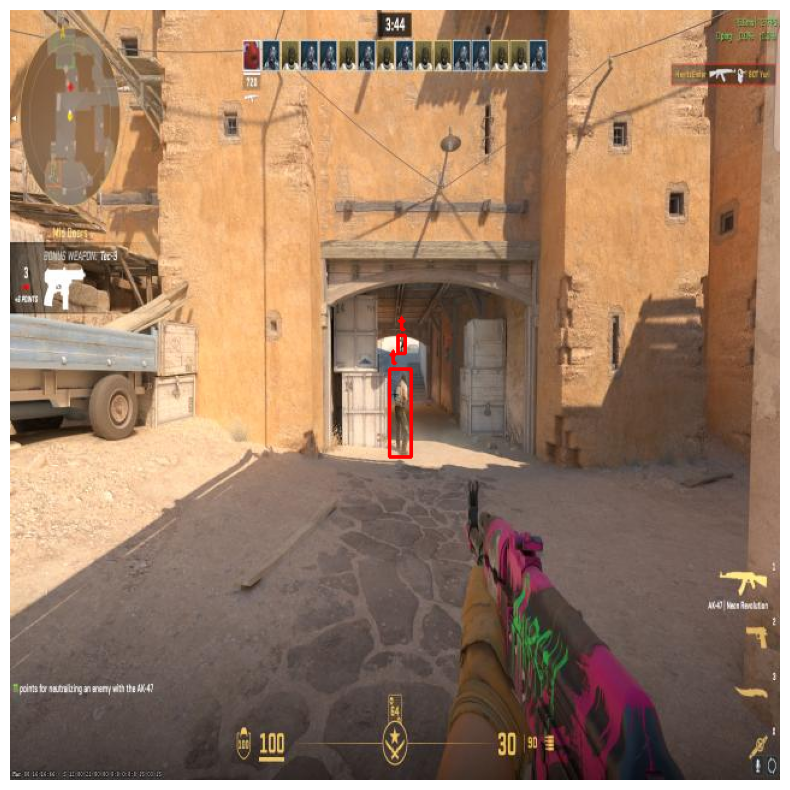

Mostrando muestra aleatoria: csdata_524-4-_png.rf.48e1bcb600aa78c11c843543a2f39023.jpg


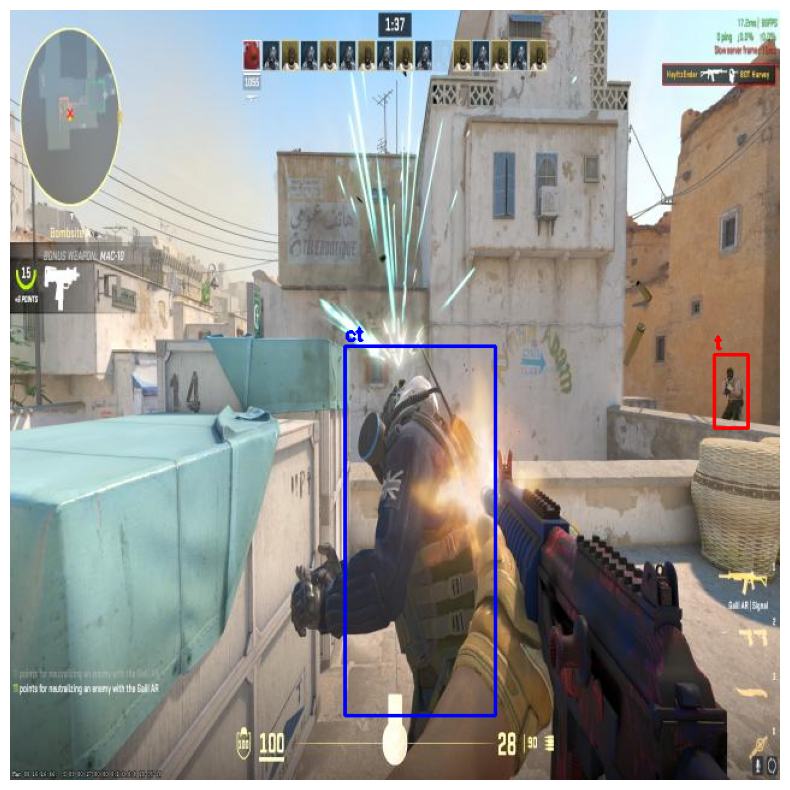

Mostrando muestra aleatoria: csdata_583-6-_png.rf.28ab80fda87860de994ba3997995ffe2.jpg


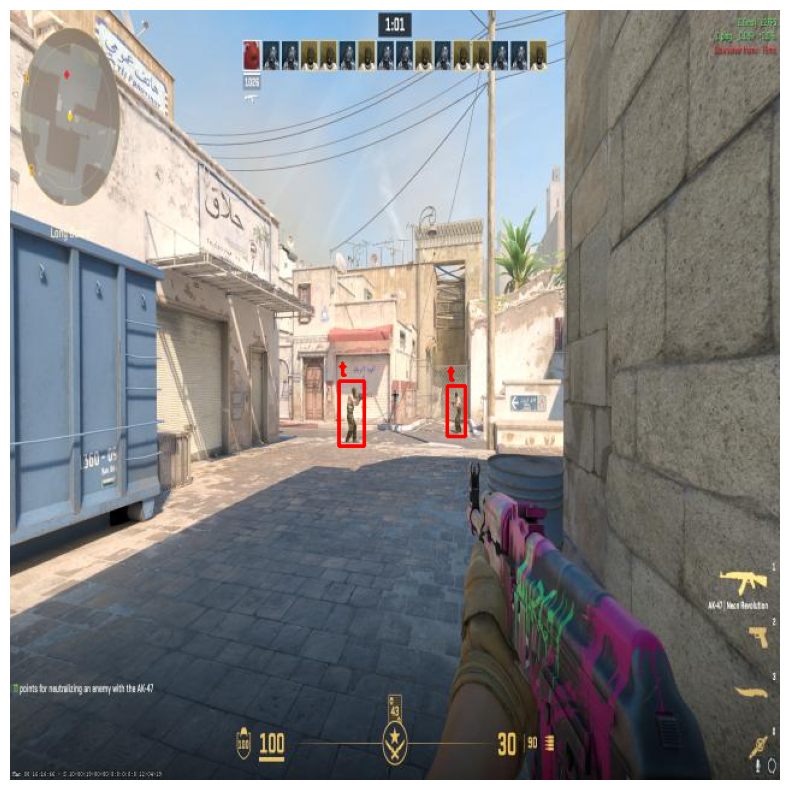

In [8]:
# Definición de rutas principales
images_dir = '/content/Counter-Strike-1/train/images'
labels_dir = '/content/Counter-Strike-1/train/labels'
class_names = dataset_info.get('names', ['ct', 't'])

# Ejecutar visualización de 3 imágenes al azar
plot_random_samples(images_dir, labels_dir, class_names, num_samples=3)

Conteo de formatos de archivos encontrados:
Formato
.jpg    2577
Name: count, dtype: int64


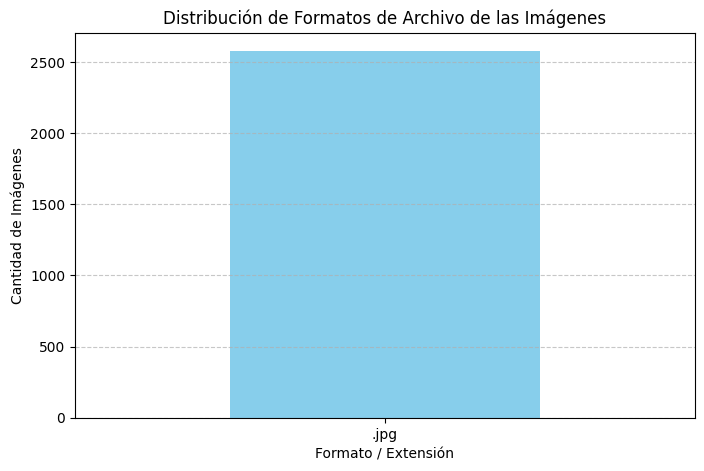

In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Obtener lista de todos los archivos en la carpeta de imágenes
if os.path.exists(images_dir):
    files = os.listdir(images_dir)
    # Extraer la extensión de cada archivo y convertirla a minúsculas
    extensions = [os.path.splitext(f)[1].lower() for f in files if os.path.isfile(os.path.join(images_dir, f))]

    # Crear un contador con Pandas
    df_ext = pd.DataFrame(extensions, columns=['Formato'])
    conteo = df_ext['Formato'].value_counts()

    # Mostrar el conteo en texto
    print("Conteo de formatos de archivos encontrados:")
    print(conteo)

    # Crear gráfico de barras
    plt.figure(figsize=(8, 5))
    conteo.plot(kind='bar', color=['skyblue', 'salmon', 'lightgreen', 'orange'])
    plt.title('Distribución de Formatos de Archivo de las Imágenes')
    plt.xlabel('Formato / Extensión')
    plt.ylabel('Cantidad de Imágenes')
    plt.xticks(rotation=0)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()
else:
    print(f"No se encontró la ruta de imágenes especificada: {images_dir}")

## 5. Análisis Exploratorio de Datos (EDA) Avanzado

### 5.1 Balanceo de Clases
Calculamos la distribución de las clases (`ct` y `t`) en cada una de las particiones del dataset (Entrenamiento, Validación y Prueba) para verificar su consistencia.

Frecuencia de clases por partición:


,Train,Valid,Test
Counter-Terrorist (ct),1778,522,246
Terrorist (t),1664,476,233


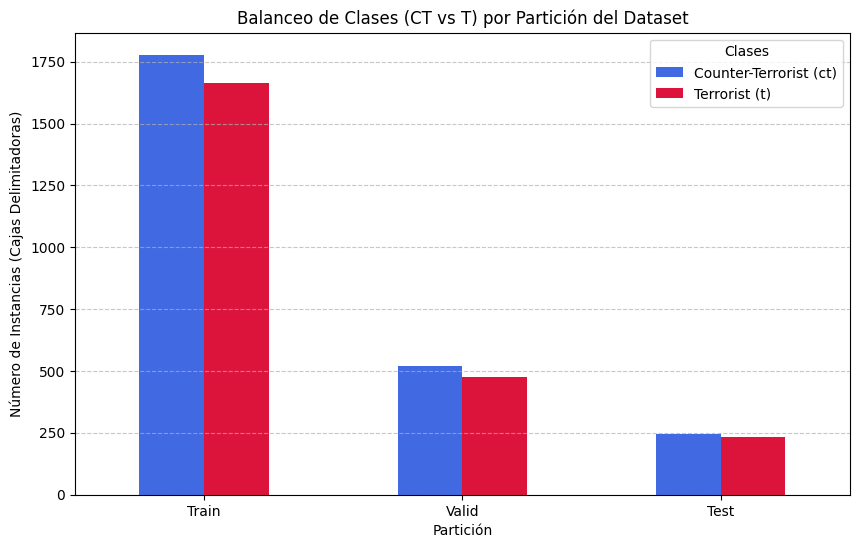

In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt

def contar_clases_en_particion(labels_dir_path):
    counts = {0: 0, 1: 0}
    if not os.path.exists(labels_dir_path):
        return counts

    for label_file in os.listdir(labels_dir_path):
        if label_file.endswith('.txt'):
            with open(os.path.join(labels_dir_path, label_file), 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if parts:
                        try:
                            cls_id = int(parts[0])
                            if cls_id in counts:
                                counts[cls_id] += 1
                        except ValueError:
                            continue
    return counts

# Rutas de las carpetas de etiquetas
particiones = {
    'Train': '/content/Counter-Strike-1/train/labels',
    'Valid': '/content/Counter-Strike-1/valid/labels',
    'Test': '/content/Counter-Strike-1/test/labels'
}

resultados = {}
for nombre, ruta in particiones.items():
    resultados[nombre] = contar_clases_en_particion(ruta)

# Crear un DataFrame para facilitar la graficación
df_balance = pd.DataFrame(resultados).rename(index={0: 'Counter-Terrorist (ct)', 1: 'Terrorist (t)'})

print("Frecuencia de clases por partición:")
display(df_balance)

# Graficar los resultados
fig, ax = plt.subplots(figsize=(10, 6))
df_balance.T.plot(kind='bar', ax=ax, color=['royalblue', 'crimson'])
plt.title('Balanceo de Clases (CT vs T) por Partición del Dataset')
plt.xlabel('Partición')
plt.ylabel('Número de Instancias (Cajas Delimitadoras)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Clases')
plt.show()

### 5.2 Análisis de Resoluciones y Relación de Aspecto (Aspect Ratio)
Analizamos las dimensiones de las imágenes de entrenamiento para conocer su tamaño y verificar si todas comparten la misma resolución y relación de aspecto.

Resumen de las dimensiones y canales de las imágenes:


,Ancho,Alto,Canales,Aspect_Ratio
count,2577.0,2577.0,2577.0,2577.0
mean,640.0,640.0,3.0,1.0
std,0.0,0.0,0.0,0.0
min,640.0,640.0,3.0,1.0
25%,640.0,640.0,3.0,1.0
50%,640.0,640.0,3.0,1.0
75%,640.0,640.0,3.0,1.0
max,640.0,640.0,3.0,1.0


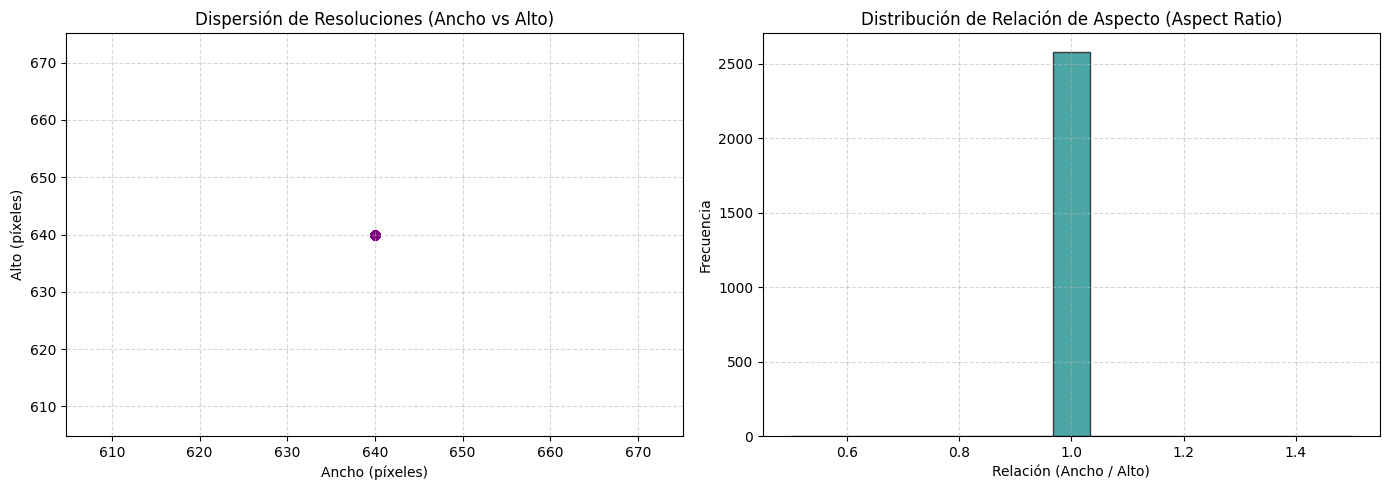

In [11]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt

resoluciones = []

if os.path.exists(images_dir):
    all_images = [f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    for img_name in all_images:
        img_path = os.path.join(images_dir, img_name)
        # Leer de forma rápida la imagen
        img = cv2.imread(img_path)
        if img is not None:
            h, w, c = img.shape
            aspect_ratio = w / h
            resoluciones.append({'Ancho': w, 'Alto': h, 'Canales': c, 'Aspect_Ratio': aspect_ratio})

    df_dims = pd.DataFrame(resoluciones)

    # Resumen estadístico
    print("Resumen de las dimensiones y canales de las imágenes:")
    display(df_dims.describe())

    # Crear gráficos de distribución
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Gráfico de dispersión de resoluciones (Ancho vs Alto)
    axes[0].scatter(df_dims['Ancho'], df_dims['Alto'], alpha=0.5, color='purple')
    axes[0].set_title('Dispersión de Resoluciones (Ancho vs Alto)')
    axes[0].set_xlabel('Ancho (píxeles)')
    axes[0].set_ylabel('Alto (píxeles)')
    axes[0].grid(True, linestyle='--', alpha=0.5)

    # Histograma de Relación de Aspecto
    axes[1].hist(df_dims['Aspect_Ratio'], bins=15, color='teal', edgecolor='black', alpha=0.7)
    axes[1].set_title('Distribución de Relación de Aspecto (Aspect Ratio)')
    axes[1].set_xlabel('Relación (Ancho / Alto)')
    axes[1].set_ylabel('Frecuencia')
    axes[1].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()
else:
    print("No se pudo acceder al directorio de imágenes de entrenamiento.")

### 5.3 Análisis de Identidad Cromática por Clase (Aislamiento de Color en HSV)
En esta sección, aislamos de forma matemática la interferencia de los colores del mapa clásico de Counter-Strike (los tonos arena, tierra y sombras del desierto) aplicando filtros de saturación y brillo. De esta forma evaluamos el porcentaje neto real de la presencia de tonos fríos/azules (Hue `[80-140]`) en los uniformes de cada bando.

In [12]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Inicialización de contadores de píxeles filtrados para cada clase
pixeles_totales_por_clase = {0: 0, 1: 0}
pixeles_azules_por_clase = {0: 0, 1: 0}

if os.path.exists(images_dir) and os.path.exists(labels_dir):
    all_images = [f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    sample_size = min(400, len(all_images))
    selected_images = random.sample(all_images, sample_size)

    for img_name in selected_images:
        lbl_name = img_name.rsplit('.', 1)[0] + '.txt'
        img_path = os.path.join(images_dir, img_name)
        lbl_path = os.path.join(labels_dir, lbl_name)

        if os.path.exists(lbl_path):
            image = cv2.imread(img_path)
            if image is None:
                continue
            h, w, _ = image.shape

            with open(lbl_path, 'r') as f:
                lines = f.readlines()

            for line in lines:
                parts = line.strip().split()
                if len(parts) == 5:
                    cls_id = int(parts[0])
                    if cls_id not in [0, 1]:
                        continue

                    x_center, y_center, bbox_w, bbox_h = map(float, parts[1:])
                    x1 = int(max(0, (x_center - bbox_w / 2) * w))
                    y1 = int(max(0, (y_center - bbox_h / 2) * h))
                    x2 = int(min(w, (x_center + bbox_w / 2) * w))
                    y2 = int(min(h, (y_center + bbox_h / 2) * h))

                    crop = image[y1:y2, x1:x2]
                    if crop.size == 0:
                        continue

                    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
                    h_channel = hsv[:, :, 0]
                    s_channel = hsv[:, :, 1]
                    v_channel = hsv[:, :, 2]

                    # Aplicar filtros (Saturación > 60 y Brillo > 30) para evitar grises, negros y el tono de la arena clara
                    color_mask = (s_channel > 60) & (v_channel > 30)
                    valid_hues = h_channel[color_mask]

                    if valid_hues.size > 0:
                        # Filtro de espectro frío/azul (Hue entre 80 y 140)
                        blue_mask = (valid_hues >= 80) & (valid_hues <= 140)
                        blue_pixels_count = np.sum(blue_mask)

                        pixeles_totales_por_clase[cls_id] += valid_hues.size
                        pixeles_azules_por_clase[cls_id] += blue_pixels_count

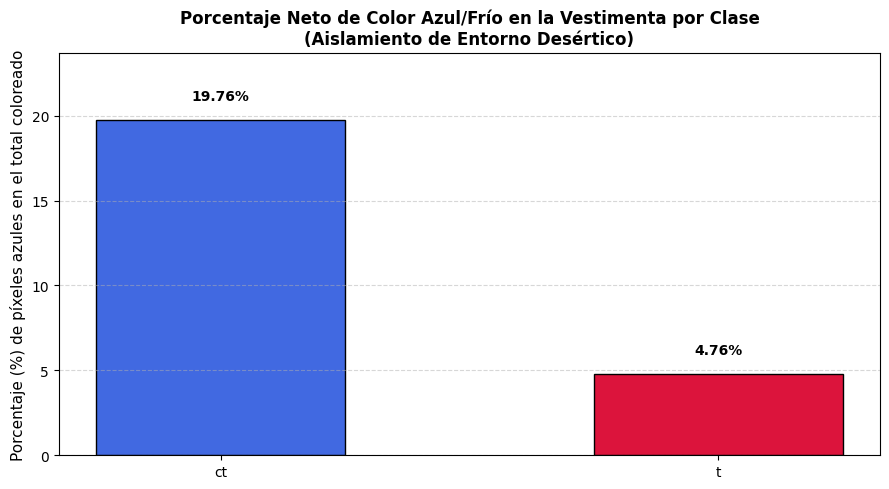

In [13]:
porcentajes_azules = {}
for cls_id in [0, 1]:
    totales = pixeles_totales_por_clase[cls_id]
    azules = pixeles_azules_por_clase[cls_id]
    # Usamos class_names que ya está definido en el notebook ['ct', 't']
    porcentajes_azules[class_names[cls_id]] = (azules / totales * 100) if totales > 0 else 0.0

# Crear gráfico comparativo final
plt.figure(figsize=(9, 5))
clases = list(porcentajes_azules.keys())
valores = list(porcentajes_azules.values())

bars = plt.bar(clases, valores, color=['royalblue', 'crimson'], edgecolor='black', width=0.5)
plt.title('Porcentaje Neto de Color Azul/Frío en la Vestimenta por Clase\n(Aislamiento de Entorno Desértico)', fontsize=12, weight='bold')
plt.ylabel('Porcentaje (%) de píxeles azules en el total coloreado', fontsize=11)
plt.ylim(0, max(valores) * 1.2 if max(valores) > 0 else 100)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1, f"{yval:.2f}%", ha='center', va='bottom', weight='bold', fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 6. Monitoreo de Experimentos (Weights & Biases)
Antes de entrenar cualquier modelo o probar diferentes configuraciones de optimizadores, inicializamos nuestra sesión en **Weights & Biases** de forma segura utilizando la API Key almacenada en los secretos de Colab.

In [14]:
import os
import wandb
from google.colab import userdata

# Desactivar la integración automática por defecto de Ultralytics para evitar ejecuciones duplicadas
os.environ["WANDB_DISABLED"] = "true"

# Configuración limpia de la nueva corrida de W&B
config_experimento = {
    "model": yolo_model_version,
    "epochs": 25,
    "imgsz": 640,
    "batch": 16,
    "optimizer": optimizer_type,
    "cache": True
}

try:
    wandb_key = userdata.get('WANDB_API_KEY')
    wandb.login(key=wandb_key)
    print("¡Inicio de sesión en W&B exitoso!")
except Exception as e:
    print(f"Advertencia en login: {e}")

# Inicializar una ejecución completamente nueva
run = wandb.init(
    entity="andresmontesdeoca",
    project="CS2-YOLO-Experiments",
    name=f"clean-{config_experimento['model'].replace('.pt', '')}-{config_experimento['optimizer']}",
    config=config_experimento,
    reinit=True
)

# Definir epoch como el eje X de todas las curvas métricas
wandb.define_metric("epoch")
wandb.define_metric("*", step_metric="epoch")
print(f"Nueva corrida inicializada correctamente. URL de seguimiento:\n{run.url}")

invalid escape sequence '\/'
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: amontesdeoca1982 (andresmontesdeoca) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


¡Inicio de sesión en W&B exitoso!


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


Nueva corrida inicializada correctamente. URL de seguimiento:
https://wandb.ai/andresmontesdeoca/CS2-YOLO-Experiments/runs/9o27a7n0


## 7. Entrenamiento del Modelo (YOLOv11)
En esta sección realizaremos la inicialización de los diferentes detectores YOLO, configuraremos el entorno de entrenamiento y ejecutaremos el ajuste fino (fine-tuning) usando la GPU activa. Al estar logueados en W&B, todos los resultados y métricas (pérdidas, mAP, consumo de hardware) se registrarán automáticamente en la nube.

In [15]:
import torch
import glob
import os
from ultralytics import YOLO

device_to_use = 0 if torch.cuda.is_available() else 'cpu'
print(f"Dispositivo de cómputo: {device_to_use}")

yaml_files = glob.glob('/content/**/data.yaml', recursive=True)
if not yaml_files:
    raise FileNotFoundError("No se detectó el archivo data.yaml.")
data_yaml_path = yaml_files[0]

# Instanciar el modelo YOLOv11
model = YOLO(config_experimento["model"])

# --- Implementación de Callbacks Explícitos para control total del log ---
def on_fit_epoch_end(trainer):
    # Extraer métricas de la época actual
    current_epoch = trainer.epoch + 1
    metrics_dict = {"epoch": current_epoch}

    # Pérdidas de entrenamiento
    if hasattr(trainer, 'loss_items') and trainer.loss_items is not None:
        loss_names = ['train/box_loss', 'train/cls_loss', 'train/dfl_loss']
        for i, val in enumerate(trainer.loss_items):
            if i < len(loss_names):
                metrics_dict[loss_names[i]] = float(val)

    # Tasas de Aprendizaje
    if hasattr(trainer, 'optimizer'):
        for i, param_group in enumerate(trainer.optimizer.param_groups):
            metrics_dict[f'lr/group_{i}'] = param_group['lr']

    # Métricas de validación por época
    if hasattr(trainer, 'metrics') and trainer.metrics:
        metrics_dict["val/box_loss"] = float(getattr(trainer, 'validator', {}).loss_items[0]) if hasattr(trainer, 'validator') and hasattr(trainer.validator, 'loss_items') else None
        metrics_dict["val/cls_loss"] = float(trainer.validator.loss_items[1]) if hasattr(trainer, 'validator') and hasattr(trainer.validator, 'loss_items') and len(trainer.validator.loss_items) > 1 else None
        metrics_dict["val/dfl_loss"] = float(trainer.validator.loss_items[2]) if hasattr(trainer, 'validator') and hasattr(trainer.validator, 'loss_items') and len(trainer.validator.loss_items) > 2 else None

        metrics_dict["metrics/precision"] = float(trainer.metrics.get('metrics/precision(B)', 0))
        metrics_dict["metrics/recall"] = float(trainer.metrics.get('metrics/recall(B)', 0))
        metrics_dict["metrics/mAP50"] = float(trainer.metrics.get('metrics/mAP50(B)', 0))
        metrics_dict["metrics/mAP50-95"] = float(trainer.metrics.get('metrics/mAP50-95(B)', 0))

    # Subir el diccionario a W&B
    wandb.log(metrics_dict)
    print(f"\n[W&B Callback] Sincronizando métricas de la Época {current_epoch}...\n")

def on_train_end(trainer):
    print("[W&B Callback] Entrenamiento finalizado localmente. Preparando subida de artefactos...")

# Registrar los callbacks manualmente en el modelo de Ultralytics
model.add_callback("on_fit_epoch_end", on_fit_epoch_end)
model.add_callback("on_train_end", on_train_end)

# Iniciar entrenamiento local (No iniciará de forma automática hasta que ejecutes la celda)
print("Modelo configurado y listo para iniciar el entrenamiento de YOLOv11.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dispositivo de cómputo: 0
Modelo configurado y listo para iniciar el entrenamiento de YOLOv11.


## 8. Evaluación en el Conjunto de Prueba (Test Set)
Procedemos a cargar los mejores pesos guardados durante el entrenamiento (`best.pt`) y a evaluar formalmente la precisión del modelo utilizando la partición de prueba independiente.

In [16]:
# Esta celda ha sido unificada y se ejecuta automáticamente dentro de la celda de entrenamiento principal.

## 9. Visualización de Predicciones del Modelo
Seleccionaremos algunas imágenes de la partición de prueba al azar, realizaremos la inferencia con nuestro modelo entrenado y dibujaremos las cajas delimitadoras resultantes junto con su confianza.

In [17]:
# Esta celda ha sido unificada y se ejecuta automáticamente dentro de la celda de entrenamiento principal.

In [18]:
if 'run' in globals() and run is not None:
    print(f"🔗 Puedes ver tu corrida en tiempo real en este enlace directo:")
    print(run.get_url())
else:
    print("La sesión de Weights & Biases no parece estar activa en esta ejecución del kernel.")

wandb: WARNING The get_url method is deprecated and will be removed in a future release. Please use `run.url` instead.


🔗 Puedes ver tu corrida en tiempo real en este enlace directo:
https://wandb.ai/andresmontesdeoca/CS2-YOLO-Experiments/runs/9o27a7n0


In [19]:
# Finalizar explícitamente la corrida para asegurar que todos los datos pendientes se suban y sincronicen a W&B
import wandb
wandb.finish()

In [20]:
# --- CELDA DE EVALUACIÓN FINAL, SUBIDA DE ARTEFACTOS Y VERIFICACIÓN DE W&B ---
import os
import glob
import wandb
import torch
from ultralytics import YOLO
from google.colab import userdata

# Asegurar dispositivo
device_to_use = 0 if torch.cuda.is_available() else 'cpu'

# Configuración de hiperparámetros con soporte para mayor número de épocas y Early Stopping (Patience = 5)
config_experimento = {
    "model": yolo_model_version,
    "epochs": 100,        # Aumentamos el límite de épocas
    "patience": 5,        # Early Stopping ajustado a 5 épocas consecutivas sin mejora
    "imgsz": 640,
    "batch": 16,
    "optimizer": optimizer_type,
    "cache": True
}

# Asegurar que la sesión de W&B está inicializada antes de registrar métricas
if wandb.run is None:
    print("[*] Inicializando una sesión activa de W&B de manera segura...")
    try:
        wandb_key = userdata.get('WANDB_API_KEY')
        wandb.login(key=wandb_key)
    except Exception as e:
        print(f"Advertencia en login: {e}")

    wandb.init(
        entity="andresmontesdeoca",
        project="CS2-YOLO-Experiments",
        name=f"earlystop-{config_experimento['model'].replace('.pt', '')}-{config_experimento['optimizer']}",
        config=config_experimento,
        reinit=True
    )

# --- Implementación optimizada y robusta de Callback ---
def on_fit_epoch_end_safe(trainer):
    current_epoch = trainer.epoch + 1
    metrics_dict = {"epoch": current_epoch}

    # Pérdidas de entrenamiento con manejo robusto de tipos
    if hasattr(trainer, 'loss_items') and trainer.loss_items is not None:
        loss_names = ['train/box_loss', 'train/cls_loss', 'train/dfl_loss']
        for i, val in enumerate(trainer.loss_items):
            if i < len(loss_names):
                try:
                    metrics_dict[loss_names[i]] = float(val)
                except (ValueError, TypeError):
                    continue

    # Tasas de Aprendizaje
    if hasattr(trainer, 'optimizer') and trainer.optimizer is not None:
        for i, param_group in enumerate(trainer.optimizer.param_groups):
            metrics_dict[f'lr/group_{i}'] = float(param_group['lr'])

    # Métricas de validación por época
    if hasattr(trainer, 'metrics') and trainer.metrics:
        try:
            if hasattr(trainer, 'validator') and hasattr(trainer.validator, 'loss_items') and trainer.validator.loss_items is not None:
                validator_losses = trainer.validator.loss_items
                if len(validator_losses) > 0: metrics_dict["val/box_loss"] = float(validator_losses[0])
                if len(validator_losses) > 1: metrics_dict["val/cls_loss"] = float(validator_losses[1])
                if len(validator_losses) > 2: metrics_dict["val/dfl_loss"] = float(validator_losses[2])
        except Exception:
            pass

        metrics_dict["metrics/precision"] = float(trainer.metrics.get('metrics/precision(B)', 0))
        metrics_dict["metrics/recall"] = float(trainer.metrics.get('metrics/recall(B)', 0))
        metrics_dict["metrics/mAP50"] = float(trainer.metrics.get('metrics/mAP50(B)', 0))
        metrics_dict["metrics/mAP50-95"] = float(trainer.metrics.get('metrics/mAP50-95(B)', 0))

    # Enviar datos a W&B de manera limpia
    if wandb.run is not None:
        wandb.log(metrics_dict)
        print(f"\n[W&B Callback] Sincronización Época {current_epoch} Completada.")

def on_train_end_safe(trainer):
    print("\n[W&B Callback] Entrenamiento finalizado. Iniciando evaluación final y sincronización...")

# Instanciar el modelo base
model = YOLO(config_experimento["model"])

# Añadir callbacks de forma segura
model.add_callback("on_fit_epoch_end", on_fit_epoch_end_safe)
model.add_callback("on_train_end", on_train_end_safe)

# 1. EJECUCIÓN DEL ENTRENAMIENTO AUTOMÁTICO OPTIMIZADO
print("[*] Iniciando el entrenamiento de YOLOv11 con Early Stopping...")
results = model.train(
    data=data_yaml_path,
    epochs=config_experimento["epochs"],
    patience=config_experimento["patience"], # Parámetro nativo de Early Stopping (5)
    imgsz=config_experimento["imgsz"],
    batch=config_experimento["batch"],
    optimizer=config_experimento["optimizer"],
    cache=config_experimento["cache"],
    device=device_to_use,
    verbose=False,  # Evita congelamiento de navegador
    plots=True,
    name=f"run_{config_experimento['model'].replace('.pt', '')}_{config_experimento['optimizer']}_es"
)

# Definición de rutas de guardado
runs_dir = "/content/runs/detect"
latest_run_dir = sorted(glob.glob(os.path.join(runs_dir, "run_*")))[-1] if glob.glob(os.path.join(runs_dir, "run_*")) else None

if latest_run_dir:
    best_weights = os.path.join(latest_run_dir, "weights", "best.pt")
    print(f"\n[+] Pesos finales guardados en: {best_weights}")

    eval_model = YOLO(best_weights)

    # Evaluación final en Validación (best_val/)
    try:
        print("[*] Evaluando mejor modelo en el conjunto de Validación...")
        val_metrics = eval_model.val(data=data_yaml_path, split='val', verbose=False)
        if wandb.run is not None:
            wandb.log({
                "best_val/mAP50": val_metrics.box.map50,
                "best_val/mAP50-95": val_metrics.box.map,
                "best_val/precision": val_metrics.box.mp,
                "best_val/recall": val_metrics.box.mr
            })
            print("[+] Métricas de validación final subidas a W&B.")
    except Exception as e:
        print(f"[!] Error durante la validación final: {e}")

    # Evaluación en Test (test/)
    try:
        print("[*] Evaluando mejor modelo en el conjunto de Prueba (Test)...")
        test_metrics = eval_model.val(data=data_yaml_path, split='test', verbose=False)
        if wandb.run is not None:
            wandb.log({
                "test/mAP50": test_metrics.box.map50,
                "test/mAP50-95": test_metrics.box.map,
                "test/precision": test_metrics.box.mp,
                "test/recall": test_metrics.box.mr
            })
            print("[+] Métricas de prueba final subidas a W&B.")
    except Exception as e:
        print(f"[!] Error durante la evaluación de test: {e}")
else:
    print("[!] No se encontró ningún directorio de ejecución para realizar las evaluaciones finales.")

[*] Inicializando una sesión activa de W&B de manera segura...


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


[*] Iniciando el entrenamiento de YOLOv11 con Early Stopping...
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Counter-Strike-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_sca

### 🏁 Cierre de Sesión y Enlace de Monitoreo (W&B)
Ejecuta la siguiente celda para finalizar formalmente la sincronización del experimento y obtener el enlace de visualización definitivo de tu panel.

[*] Cargando resultados desde: /content/runs/detect/run_yolo11n_AdamW_es/results.csv


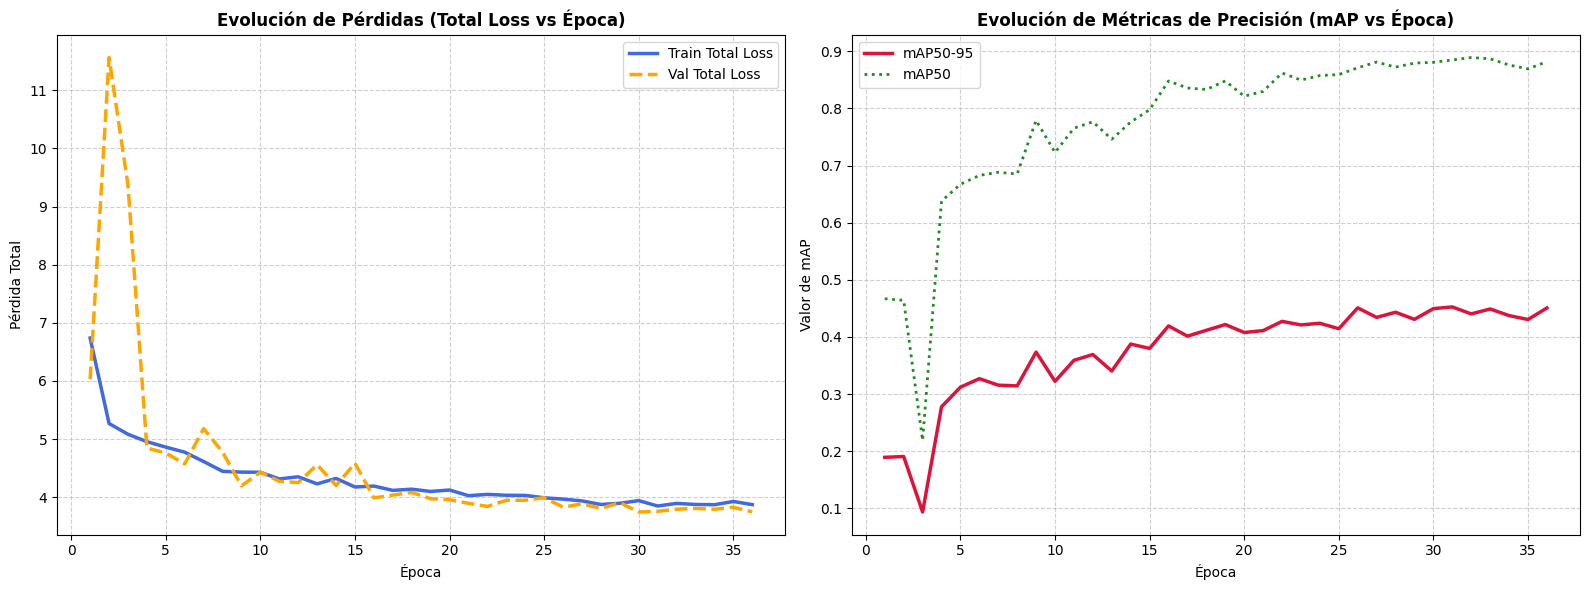

[*] Registrando gráficos interactivos directamente en Weights & Biases...
[+] Sincronización exitosa en tu panel de control de W&B.
[*] Finalizando sesión de Weights & Biases...


best_val/mAP50,▁
best_val/mAP50-95,▁
best_val/precision,▁
best_val/recall,▁
epoch,▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇███
lr/group_0,▁▅█████▇▇▇▇▇▇▇▇▇▇▆▆▆▆▆▆▆▆▆▅▅▅▅▅▅▅▅▅▄▄
lr/group_1,▁▅█████▇▇▇▇▇▇▇▇▇▇▆▆▆▆▆▆▆▆▆▅▅▅▅▅▅▅▅▅▄▄
lr/group_2,█▅▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
metrics/mAP50,▄▄▁▅▆▆▆▆▇▆▇▇▇▇▇█▇▇█▇▇████████████████
metrics/mAP50-95,▃▃▁▅▅▆▅▅▆▅▆▆▆▇▇▇▇▇▇▇▇█▇▇▇████████████
+6,...


In [21]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import wandb

# 1. Localizar el último directorio de entrenamiento donde se guardaron los resultados de YOLOv11
runs_dir = "/content/runs/detect"
runs_folders = sorted(glob.glob(os.path.join(runs_dir, "run_*_es*")))

if runs_folders:
    latest_run_dir = runs_folders[-1]
    results_csv_path = os.path.join(latest_run_dir, "results.csv")

    if os.path.exists(results_csv_path):
        print(f"[*] Cargando resultados desde: {results_csv_path}")
        df_results = pd.read_csv(results_csv_path)

        # Limpiar nombres de columnas (eliminar espacios en blanco sobrantes)
        df_results.columns = [c.strip() for c in df_results.columns]

        # Crear figura con 2 subplots
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))

        # 1. Gráfico de Epoch vs Loss (Train vs Val)
        train_loss = df_results['train/box_loss'] + df_results['train/cls_loss'] + df_results['train/dfl_loss']
        val_loss = df_results['val/box_loss'] + df_results['val/cls_loss'] + df_results['val/dfl_loss']
        epochs = df_results['epoch']

        axes[0].plot(epochs, train_loss, label="Train Total Loss", color="royalblue", linewidth=2.5)
        axes[0].plot(epochs, val_loss, label="Val Total Loss", color="orange", linestyle="--", linewidth=2.5)
        axes[0].set_title("Evolución de Pérdidas (Total Loss vs Época)", fontsize=12, weight="bold")
        axes[0].set_xlabel("Época", fontsize=10)
        axes[0].set_ylabel("Pérdida Total", fontsize=10)
        axes[0].grid(True, linestyle="--", alpha=0.6)
        axes[0].legend()

        # 2. Gráfico de Epoch vs mAP50-95
        map50_95 = df_results['metrics/mAP50-95(B)']
        map50 = df_results['metrics/mAP50(B)']

        axes[1].plot(epochs, map50_95, label="mAP50-95", color="crimson", linewidth=2.5)
        axes[1].plot(epochs, map50, label="mAP50", color="forestgreen", linestyle=":", linewidth=2)
        axes[1].set_title("Evolución de Métricas de Precisión (mAP vs Época)", fontsize=12, weight="bold")
        axes[1].set_xlabel("Época", fontsize=10)
        axes[1].set_ylabel("Valor de mAP", fontsize=10)
        axes[1].grid(True, linestyle="--", alpha=0.6)
        axes[1].legend()

        plt.tight_layout()
        plt.show()

        # 2. Registrar las gráficas en el run actual activo de W&B
        if wandb.run is not None:
            print("[*] Registrando gráficos interactivos directamente en Weights & Biases...")
            wandb.log({
                "plots/epoch_vs_loss_chart": wandb.Image(fig),
                "plots/epoch_vs_loss": wandb.plot.line_series(
                    xs=epochs.tolist(),
                    ys=[train_loss.tolist(), val_loss.tolist()],
                    keys=["Train Loss", "Val Loss"],
                    title="Pérdidas Totales por Época",
                    xname="Época"
                ),
                "plots/epoch_vs_map50_95": wandb.plot.line_series(
                    xs=epochs.tolist(),
                    ys=[map50_95.tolist(), map50.tolist()],
                    keys=["mAP50-95", "mAP50"],
                    title="mAP Metrics por Época",
                    xname="Época"
                )
            })
            print("[+] Sincronización exitosa en tu panel de control de W&B.")

            # Finalizar la sesión después de sincronizar
            print("[*] Finalizando sesión de Weights & Biases...")
            wandb.finish()
        else:
            print("[!] No se detectó ninguna sesión activa de W&B en ejecución para subir métricas.")
    else:
        print(f"[!] No se pudo encontrar el archivo results.csv en {results_csv_path}")
else:
    print("[!] No se encontró ninguna carpeta de ejecución en runs/detect/")